# 4. Image Segmentation

The animations generated can be viewed using the following link: 

https://iiithydstudents-my.sharepoint.com/:f:/g/personal/sudhanva_joshi_students_iiit_ac_in/El5oOaJ8MdtNqqdn_yMFdycBLXc5YlVplBUjnFQhtwm6aA?e=7lqPQn

In [ ]:
# Imports necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import hashlib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import silhouette_score
from scipy.stats import multivariate_normal
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from matplotlib.animation import FuncAnimation
import matplotlib.image as mpimg

# Generate seed based on my college ID.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)

# Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="rocket", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    plt.text(0.95, -0.1, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.tight_layout()
    plt.show()

def coordplot(ax, title, x_label, y_label):
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)


# Loaded and Preprocessed the Data.
image_path_1 = '../data/satellite_1.png'
image_path_2 = '../data/satellite_2.png'

Seed generated: 1027714457


In [2]:
class GMM:
    """
    A Gaussian Mixture Model implementation from scratch using the EM algorithm.
    """
    def __init__(self, k, max_iter=100, tol=1e-4):
        self.k = k
        self.max_iter = max_iter
        self.tol = tol  # Tolerance for convergence
        self.pi = None  # Mixing coefficients
        self.mu = None  # Means of the Gaussians
        self.sigma = None # Covariance matrices of the Gaussians
        self.likelihood_history = []
        self.responsibilities = None

    def _initialize_parameters(self, X):
        """Initializes model parameters."""
        n_samples, n_features = X.shape
        self.pi = np.full(self.k, 1/self.k)
        random_indices = rng.choice(n_samples, self.k, replace=False)
        self.mu = X[random_indices]
        self.sigma = np.array([np.eye(n_features)] * self.k)

    def _e_step(self, X):
        """Performs the Expectation (E) step."""
        n_samples = X.shape[0]
        self.responsibilities = np.zeros((n_samples, self.k))
        for i in range(self.k):
            pdf = multivariate_normal.pdf(X, mean=self.mu[i], cov=self.sigma[i], allow_singular=True)
            self.responsibilities[:, i] = self.pi[i] * pdf
        
        # Add a small constant to prevent division by zero
        sum_resp = np.sum(self.responsibilities, axis=1, keepdims=True)
        self.responsibilities = self.responsibilities / (sum_resp + 1e-9)

    def _m_step(self, X):
        """Performs the Maximization (M) step."""
        n_samples, n_features = X.shape
        Nk = np.sum(self.responsibilities, axis=0)
        
        self.pi = Nk / n_samples
        self.mu = (self.responsibilities.T @ X) / (Nk[:, np.newaxis] + 1e-9)
        
        for i in range(self.k):
            diff = X - self.mu[i]
            # Add a small epsilon for numerical stability
            epsilon = 1e-6 * np.eye(n_features)
            self.sigma[i] = (diff.T * self.responsibilities[:, i]) @ diff / (Nk[i] + 1e-9) + epsilon

    def _calculate_log_likelihood(self, X):
        """Calculates the log-likelihood of the data."""
        likelihood = np.zeros(X.shape[0])
        for i in range(self.k):
            pdf = multivariate_normal.pdf(X, mean=self.mu[i], cov=self.sigma[i], allow_singular=True)
            likelihood += self.pi[i] * pdf
        return np.sum(np.log(likelihood + 1e-9))
        
    def fit(self, X):
        """Fits the GMM to the dataset X using the EM algorithm."""
        self._initialize_parameters(X)
        for i in range(self.max_iter):
            self._e_step(X)
            self._m_step(X)
            log_likelihood = self._calculate_log_likelihood(X)
            self.likelihood_history.append(log_likelihood)
            
            if i > 0 and abs(log_likelihood - self.likelihood_history[-2]) < self.tol:
                print(f"Converged at iteration {i+1}.")
                break
        else:
             print(f"Reached max iterations ({self.max_iter}) without convergence.")

    def getMembership(self):
        """Returns the membership values (responsibilities) Y_ic."""
        if self.responsibilities is None:
            raise ValueError("Model has not been fitted yet. Call fit() first.")
        return self.responsibilities

    def getLikelihood(self):
        """Returns the final log-likelihood of the dataset."""
        if not self.likelihood_history:
            raise ValueError("Model has not been fitted yet. Call fit() first.")
        return self.likelihood_history[-1]

    def drawLikelihood(self):
        """Plots the log-likelihood vs. iteration."""
        plt.figure(figsize=(10, 6))
        plt.plot(range(1, len(self.likelihood_history) + 1), self.likelihood_history, marker='o')
        plotinfo(f'Log-Likelihood vs. Iteration for k={self.k}', 'Iteration', 'Log-Likelihood')
        
        


## 4.1 Image Segmentation

In [3]:
class GMMVisualizer(GMM):
    """
    An extension of the GMM class to store parameter history for visualization.
    """
    def __init__(self, k, max_iter=100, tol=1e-4):
        super().__init__(k, max_iter, tol)
        # Add lists to store the history of parameters
        self.mu_history = []
        self.responsibilities_history = []

    def fit(self, X):
        """
        Fits the GMM and stores the history of mu and responsibilities
        at each iteration.
        """
        self._initialize_parameters(X)
        
        for i in range(self.max_iter):
            # E-Step and M-Step are called from the parent GMM class
            self._e_step(X)
            self._m_step(X)

            # Store the state of the model at this iteration
            self.mu_history.append(self.mu.copy())
            self.responsibilities_history.append(self.responsibilities.copy())
            
            # Calculate log-likelihood and check for convergence
            log_likelihood = self._calculate_log_likelihood(X)
            self.likelihood_history.append(log_likelihood)
            
            if i > 0 and abs(log_likelihood - self.likelihood_history[-2]) < self.tol:
                print(f"Converged at iteration {i+1}.")
                break
        else:
             print(f"Reached max iterations ({self.max_iter}) without convergence.")

def process_and_visualize_image(image_path, k=3, max_iter=50):
    """
    Loads a satellite image, performs segmentation, and generates a
    dynamic visualization video of the GMM fitting process.
    """
    print(f"--- Processing {image_path} ---")
    
    # 1. Load and prepare the image data
    image = mpimg.imread(image_path)
    # Ensure image data is in float format [0, 1] for GMM
    if image.dtype == np.uint8:
        image = image / 255.0
        
    height, width, channels = image.shape
    # Flatten the image from (H, W, 3) to (H*W, 3)
    X_image = image.reshape(-1, channels)

    # 2. Fit the GMM and capture the history
    gmm = GMMVisualizer(k=k, max_iter=max_iter)
    gmm.fit(X_image)

    print("\nGenerating final segmented image...")
    # Get the final cluster assignments
    final_responsibilities = gmm.responsibilities_history[-1]
    labels = np.argmax(final_responsibilities, axis=1)
    
    # Replace each pixel with the mean color of its assigned cluster
    final_mu = gmm.mu_history[-1]
    segmented_X = final_mu[labels]
    segmented_image = segmented_X.reshape(height, width, channels)

    # Plot the final result
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    ax1.imshow(image)
    ax1.set_title("Original Image")
    ax1.axis('off')
    
    ax2.imshow(segmented_image)
    ax2.set_title(f"Final Segmented Image (k={k})")
    ax2.axis('off')
    
    plotinfo(f'Final Segmentation for {image_path}', '', '')

    print("Generating dynamic visualization video...")
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))
    fig.text(0.95, 0.05, username, ha='right', va='center', fontsize=10, color='gray', alpha=0.7)

    # Panel 1: Original Image (static)
    ax1.imshow(image)
    ax1.set_title("Original Image")
    ax1.axis('off')

    # Panel 2: Segmented Image (dynamic) - get the initial object
    im_center = ax2.imshow(image) # Start with original, will be updated
    ax2.set_title("Segmented (Iteration 1)")
    ax2.axis('off')

    # Panel 3: Likelihood Plot (dynamic) - get the initial object
    ax3.set_xlim(1, len(gmm.likelihood_history))
    ax3.set_ylim(min(gmm.likelihood_history) - 100, max(gmm.likelihood_history) + 100)
    ax3.set_xlabel("Iteration")
    ax3.set_ylabel("Log-Likelihood")
    ax3.set_title("Likelihood Convergence")
    ax3.grid(True)
    line, = ax3.plot([], [], marker='o')

    # This function is called for each frame of the animation
    def update(frame):
        # Update Panel 2
        responsibilities = gmm.responsibilities_history[frame]
        labels = np.argmax(responsibilities, axis=1)
        mu = gmm.mu_history[frame]
        segmented_X_frame = mu[labels]
        current_segmented_image = segmented_X_frame.reshape(height, width, channels)
        im_center.set_data(current_segmented_image)
        ax2.set_title(f"Segmented (Iteration {frame + 1})")

        # Update Panel 3
        x_data = range(1, frame + 2)
        y_data = gmm.likelihood_history[:frame+1]
        line.set_data(x_data, y_data)
        
        return im_center, line

    # Create the animation
    anim = FuncAnimation(fig, update, frames=len(gmm.likelihood_history), blit=True)
    
    # Save the video
    output_filename = f"{image_path.split('.')[0]}_segmentation.mp4"
    anim.save(output_filename, writer='ffmpeg', dpi=150)
    print(f"Video saved as '{output_filename}'")
    plt.close() # Close figure to prevent double display

## 4.2 Dynamic Visualization Video

--- Processing data/satellite_1.png ---
Reached max iterations (50) without convergence.

Generating final segmented image...


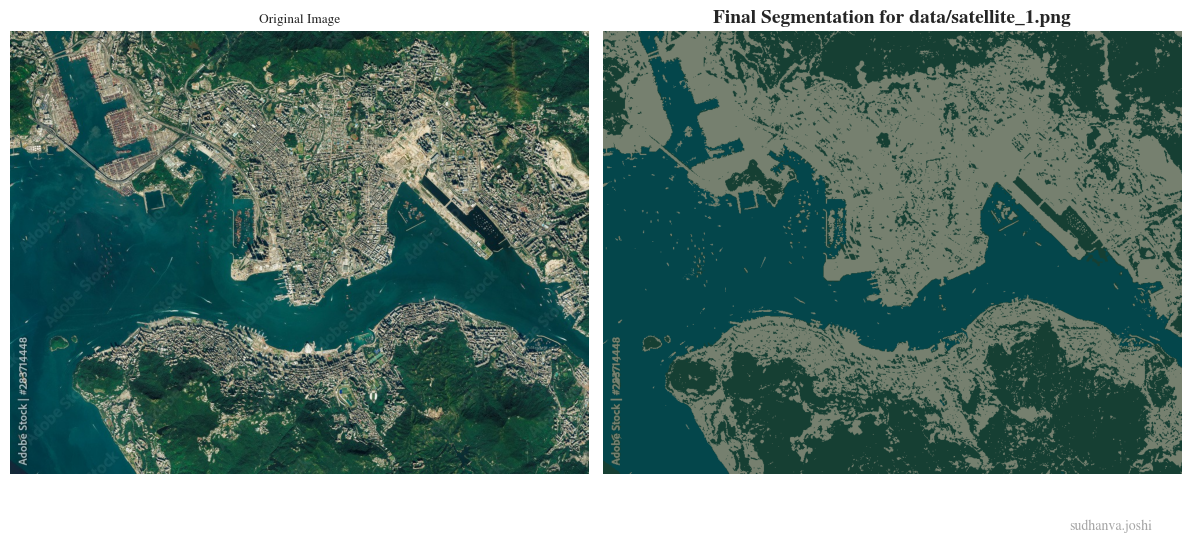

Generating dynamic visualization video...
Video saved as 'data/satellite_1_segmentation.mp4'
--- Processing data/satellite_2.png ---
Reached max iterations (50) without convergence.

Generating final segmented image...


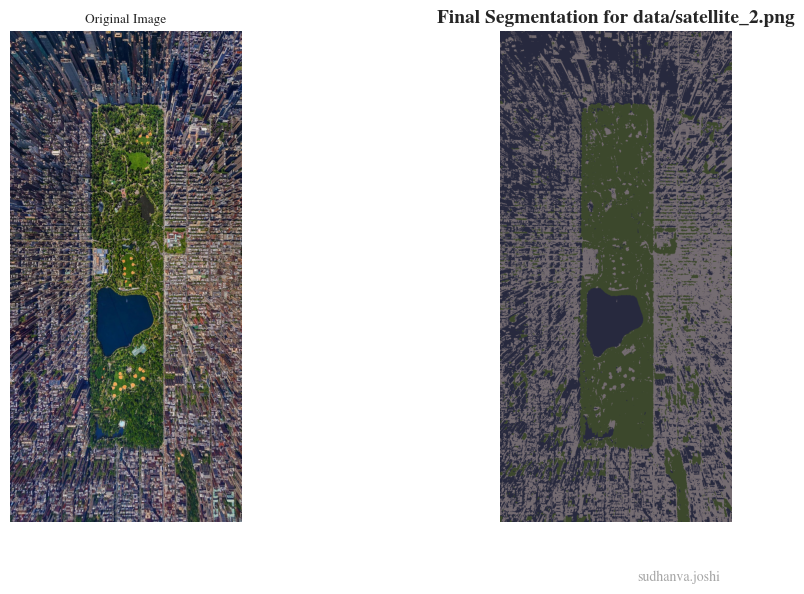

Generating dynamic visualization video...
Video saved as 'data/satellite_2_segmentation.mp4'


In [4]:
import os
if not os.path.exists('data'):
    os.makedirs('data')
if not os.path.exists('data/satellite_1.png'):
    # Create a simple placeholder image
    dummy_img_1 = np.random.rand(100, 100, 3)
    mpimg.imsave('data/satellite_1.png', dummy_img_1)
if not os.path.exists('data/satellite_2.png'):
    dummy_img_2 = np.random.rand(100, 100, 3)
    mpimg.imsave('data/satellite_2.png', dummy_img_2)

process_and_visualize_image('data/satellite_1.png', k=3)
process_and_visualize_image('data/satellite_2.png', k=3)